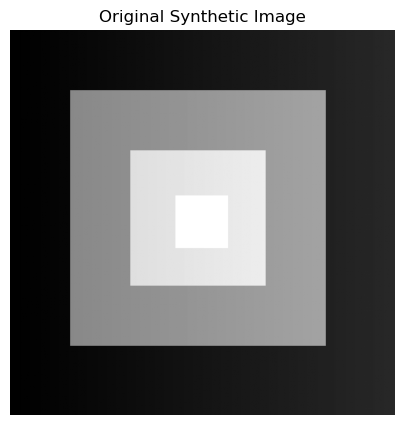

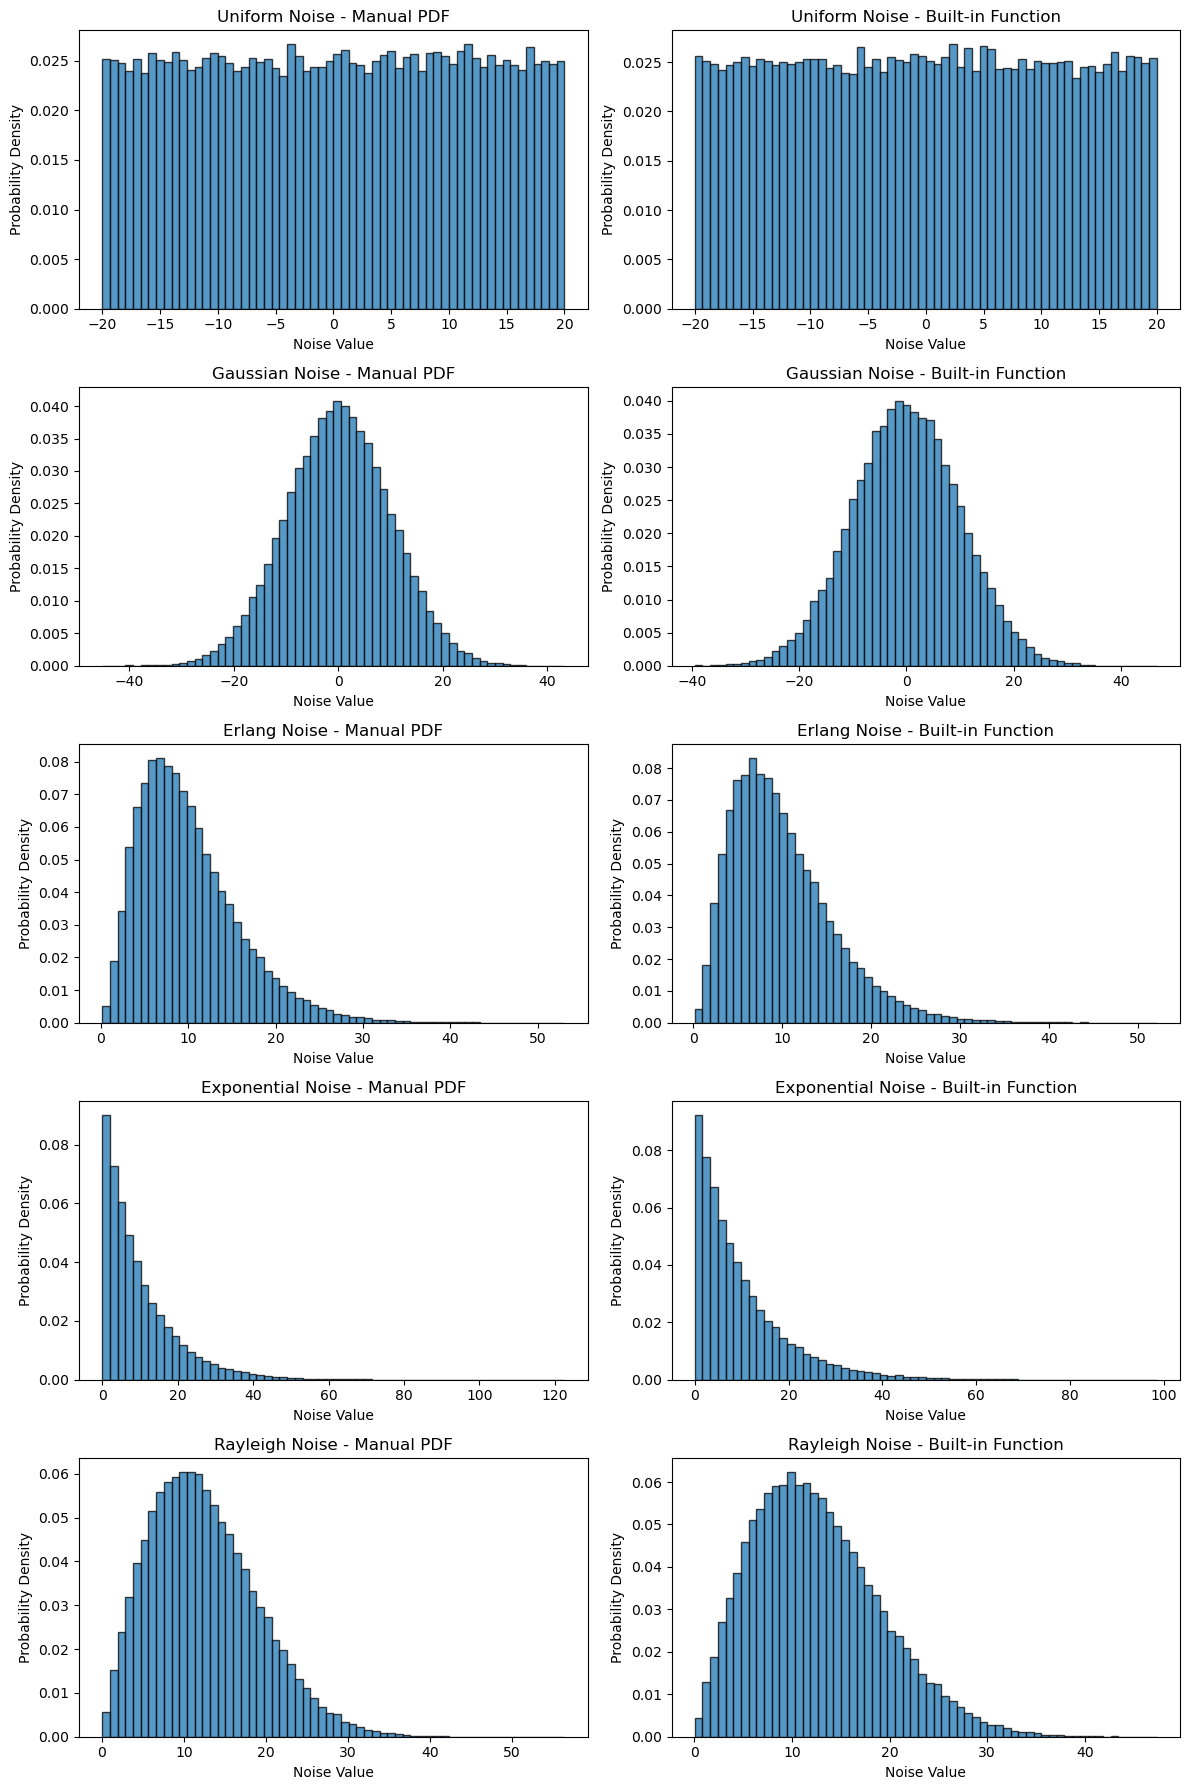

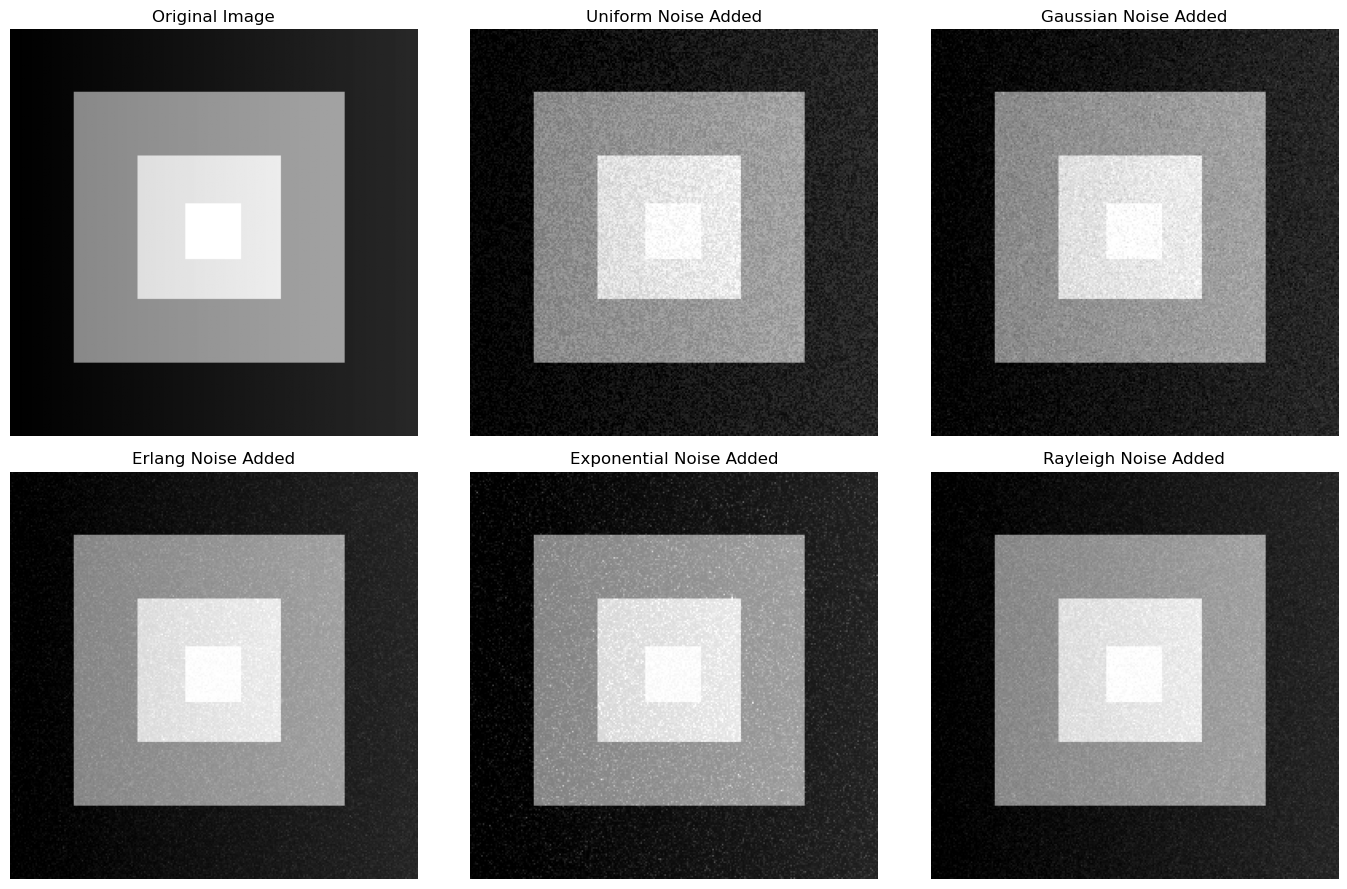

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# Synthetic grayscale image
size = 256
image = np.zeros((size, size), dtype=float)
image[40:210, 40:210] = 130
image[80:170, 80:170] = 210
image[110:145, 110:145] = 255
image = np.clip(image + np.linspace(0, 40, size), 0, 255)

# Distribution parameters
a, b = -20, 20
mu, sigma = 0, 10
k, rate = 3, 0.3
exp_rate = 0.1
rayleigh_sigma = 10

# Uniform noise: manual PDF-based generation
u = rng.random(image.shape)
uniform_manual = a + (b - a) * u
uniform_builtin = rng.uniform(a, b, image.shape)

# Gaussian noise: Box-Muller method
u1 = np.maximum(rng.random(image.shape), 1e-10)
u2 = rng.random(image.shape)
gaussian_manual = mu + sigma * np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
gaussian_builtin = rng.normal(mu, sigma, image.shape)

# Erlang noise: sum of k exponential random variables
erlang_manual = sum(
    -np.log(np.maximum(rng.random(image.shape), 1e-10)) / rate
    for _ in range(k)
)
erlang_builtin = rng.gamma(shape=k, scale=1/rate, size=image.shape)

# Exponential noise: inverse CDF method
u = np.maximum(rng.random(image.shape), 1e-10)
exponential_manual = -np.log(u) / exp_rate
exponential_builtin = rng.exponential(scale=1/exp_rate, size=image.shape)

# Rayleigh noise: inverse CDF method
u = np.maximum(rng.random(image.shape), 1e-10)
rayleigh_manual = rayleigh_sigma * np.sqrt(-2 * np.log(u))
rayleigh_builtin = rng.rayleigh(rayleigh_sigma, image.shape)

# Distribution names and generated noise
noise_data = [
    ("Uniform", uniform_manual, uniform_builtin, (a+b)/2),
    ("Gaussian", gaussian_manual, gaussian_builtin, mu),
    ("Erlang", erlang_manual, erlang_builtin, k/rate),
    ("Exponential", exponential_manual, exponential_builtin, 1/exp_rate),
    ("Rayleigh", rayleigh_manual, rayleigh_builtin,
     rayleigh_sigma * np.sqrt(np.pi/2))
]

# Display original image
plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Synthetic Image")
plt.axis("off")
plt.show()

# Compare manually generated and built-in distributions
fig, axes = plt.subplots(5, 2, figsize=(12, 18))

for i, (name, manual, builtin, mean_value) in enumerate(noise_data):
    axes[i, 0].hist(manual.ravel(), bins=60, density=True,
                    alpha=0.75, edgecolor="black")
    axes[i, 0].set_title(name + " Noise - Manual PDF")
    axes[i, 0].set_xlabel("Noise Value")
    axes[i, 0].set_ylabel("Probability Density")

    axes[i, 1].hist(builtin.ravel(), bins=60, density=True,
                    alpha=0.75, edgecolor="black")
    axes[i, 1].set_title(name + " Noise - Built-in Function")
    axes[i, 1].set_xlabel("Noise Value")
    axes[i, 1].set_ylabel("Probability Density")

plt.tight_layout()
plt.show()

# Add zero-mean versions of noise to the image
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

axes[0, 0].imshow(image, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Image")
axes[0, 0].axis("off")

for i, (name, manual, builtin, mean_value) in enumerate(noise_data):
    noisy_image = np.clip(image + (manual - mean_value), 0, 255)

    ax = axes.flat[i + 1]
    ax.imshow(noisy_image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name + " Noise Added")
    ax.axis("off")

plt.tight_layout()
plt.show()